# Improvements: Can we trust these numbers?

**Paper:** van der Horst et al., *High Stakes, Low Certainty: Evaluating the Efficacy of High-Level Indicators of Compromise in Ransomware Attribution*, USENIX Security 2025.

This notebook adds to the authors' `data_analysis.ipynb` without changing it. It reads the same two data files and asks one question throughout: **can a reader trust the numbers, and what do they really say?**

**Our main message:** a TTP (an attacker's tactics, techniques and procedures) is a *clue*, not *proof*. Think of it like a criminal's *modus operandi*: a similar way of working links cases and narrows the list of suspects, but it cannot identify one person on its own.

The notebook has three parts:

| Part | Plain question | Sections |
|---|---|---|
| **A. Trust** | Can anyone rerun this, and do the numbers and sources check out? | A1 environment, A2 number ledger, A2b full-table check, A3 source audit, A4 summary |
| **B. Method** | Are the measurements correct and is the result more than chance? | B1 corrected metric, B2 shuffle test, B2b nearest-match test |
| **C. Practice** | What does this mean for an analyst? | C1 techniques everyone uses, C2 clue scorecard |

Every section starts with **Question**, **What we do** and **How to read it**. Tables are saved as CSV files in `../results/improvements/`. Run with **Run All**; it takes under a minute.

In [1]:
# Setup: libraries, folders and settings used by every section
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

DATA_DIR = Path("../data")                          # the authors' data folder (data.zip)
CISA_PDF_DIR = Path("../CISA_StopRansomware_Reports")  # the archived CISA advisories
OUT_DIR = Path("../results/improvements")           # everything this notebook writes
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42        # fixes the random shuffles so every run gives the same answer
N_SHUFFLES = 2000

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

def save(df, name):
    # Save a table as CSV so it can be reused in the report or a dashboard.
    path = OUT_DIR / f"{name}.csv"
    df.to_csv(path, index=False)
    print(f"Saved: {path}")

## A1. Environment check

**Question:** Will this run on my computer?

**What we do:** Print the software versions in use. Warn if Python is 3.14 or newer, because the authors' locked `numpy 2.1.3` cannot be installed there. That was the first obstacle we hit when following the README.

**How to read it:** Every row should show **OK**. The cell also writes `REPRODUCE.md`, a short set of setup steps that worked for us, and a one-line fix for the authors' `pyproject.toml`.

In [2]:
checks = pd.DataFrame([
    {"item": "Python", "version": platform.python_version(),
     "status": "OK" if (3, 11) <= sys.version_info[:2] < (3, 14) else "WARNING: use Python 3.11-3.13"},
    {"item": "pandas", "version": pd.__version__, "status": "OK"},
    {"item": "numpy", "version": np.__version__, "status": "OK"},
    {"item": "scikit-learn", "version": sklearn.__version__, "status": "OK"},
    {"item": "matplotlib", "version": matplotlib.__version__, "status": "OK"},
    {"item": "Operating system", "version": f"{platform.system()} {platform.release()} ({platform.machine()})", "status": "OK"},
])
display(checks)

(OUT_DIR / "REPRODUCE.md").write_text('''# How we reproduced the analysis

Tested on a 2020 Intel MacBook Air (8 GB RAM) with VS Code.

1. Use Python 3.11-3.13. The locked numpy 2.1.3 has no installer for Python 3.14,
   so `poetry install` fails there. With Anaconda:
       conda create -y -n p3 python=3.12
       conda activate p3
2. Inside the `code/` folder:
       poetry env use python
       poetry install --no-root
3. Register the environment so the notebook can find it:
       poetry run python -m ipykernel install --user --name p3-venv --display-name "P3 (.venv)"
4. In VS Code: Select Kernel > Jupyter Kernel > "P3 (.venv)", then Run All.
   If an import fails with "CPU dispatcher tracer already initialized", restart the kernel.

Suggested fix for pyproject.toml (stops Poetry from picking an unsupported Python):
    python = ">=3.11,<3.14"
''')
print(f"Saved: {OUT_DIR / 'REPRODUCE.md'}")

,item,version,status
0,Python,3.12.11,OK
1,pandas,2.2.3,OK
2,numpy,2.1.3,OK
3,scikit-learn,1.6.1,OK
4,matplotlib,3.10.0,OK
5,Operating system,Darwin 24.6.0 (x86_64),OK


Saved: ../results/improvements/REPRODUCE.md


## Load the data and define the measures

The two files are the authors' own inputs. Each row is a report (company data) or a threat group (CISA data). Each of the 887 columns is one ATT&CK *tactic + technique + sub-technique* combination: **1** means it was seen, **0** means it was not.

The two similarity functions are copied unchanged from the authors' notebook. In plain words:

- **Overlap (paper's Eq. 1):** shared techniques ÷ size of the *smaller* list.
- **Containment (paper's Eq. 2):** shared techniques ÷ size of the *first* list.

In [3]:
comp_df = pd.read_pickle(DATA_DIR / "comp_data_ttps.pkl")        # 27 company reports
cisa_df = pd.read_pickle(DATA_DIR / "cisa_data_normalized.pkl")  # 13 CISA threat groups
print("Company reports:", comp_df.shape, "| CISA groups:", cisa_df.shape)

# --- copied from the authors' notebook ---
def containment_similarity(vect1, vect2):
    bool_vect1 = np.asarray(vect1).astype(bool)
    bool_vect2 = np.asarray(vect2).astype(bool)
    intersection = np.logical_and(bool_vect1, bool_vect2)
    return intersection.sum() / bool_vect1.sum()

def overlap_similarity(vect1, vect2):
    bool_vect1 = np.asarray(vect1).astype(bool)
    bool_vect2 = np.asarray(vect2).astype(bool)
    intersection = np.logical_and(bool_vect1, bool_vect2)
    return intersection.sum() / min(bool_vect1.sum(), bool_vect2.sum())
# --- added by us ---
def pairwise_mean(df, sim):
    # Average similarity over every pair of rows (row i compared with each later row j).
    rows = [df.iloc[i].to_numpy() for i in range(len(df))]
    vals = [sim(rows[i], rows[j]) for i in range(len(rows)) for j in range(i + 1, len(rows))]
    return float(np.mean(vals)), vals

def group_profiles(df):
    # Combine all reports of one group into a single profile (seen in any report = 1),
    # sorted from most to fewest techniques, exactly as the authors do.
    prof = df.groupby(level="TA").agg(lambda x: x.any().astype(int))
    return prof.loc[prof.sum(axis=1).sort_values(ascending=False).index]

def within_group_mean(df, sim):
    # Paper's Table 5: average similarity between reports of the SAME group,
    # for groups with at least two reports.
    per_group = {}
    for ta in df.index.get_level_values("TA").unique():
        g = df.loc[ta]
        if len(g) >= 2:
            per_group[ta] = pairwise_mean(g, sim)[0]
    return float(np.mean(list(per_group.values()))), per_group

comp_prof = group_profiles(comp_df)
cisa_prof = cisa_df.loc[cisa_df.sum(axis=1).sort_values(ascending=False).index]
labels = comp_df.index.get_level_values("TA").to_numpy()

Company reports: (27, 887) | CISA groups: (13, 887)


## A2. Number ledger: does every reported number come out of the code?

**Question:** If I rerun the authors' code, do I get the numbers printed in the paper?

**What we do:** Recompute 15 numbers from Section 4.2 and Tables 5 to 7 with the authors' own method, then compare each one with the paper at the paper's rounding.

**How to read it:** ✅ means the number matches exactly. This confirms the *computation*. It does not check whether the right formula was used; that is section B1.

In [4]:
ledger = []
def add(item, where, paper, value, decimals):
    ledger.append({"result": item, "where in paper": where, "paper": paper,
                   "reproduced": round(value, decimals),
                   "match": "✅" if round(value, decimals) == paper else "❌"})

y = comp_df.index.get_level_values("TA")
add("Silhouette score, Euclidean", "Sec. 4.2", -0.0864, silhouette_score(comp_df, y, metric="euclidean"), 4)
add("Silhouette score, cosine", "Sec. 4.2", -0.0873, silhouette_score(comp_df, y, metric="cosine"), 4)

t5_avg, t5 = within_group_mean(comp_df, containment_similarity)   # authors' code uses containment here
for ta, paper in {"Blackcat": 0.56, "Lockbit": 0.41, "Play": 0.28, "Blackbasta": 0.36, "Royal": 0.25}.items():
    add(f"Same-group similarity: {ta}", "Table 5", paper, t5[ta], 2)
add("Same-group similarity: average", "Table 5", 0.37, t5_avg, 2)

add("Different-group similarity, company", "Table 6a / Sec. 4.2", 0.21, pairwise_mean(comp_prof, containment_similarity)[0], 2)
add("Different-group similarity, CISA", "Table 6b / Sec. 4.2", 0.21, pairwise_mean(cisa_prof, containment_similarity)[0], 2)

COMP_TO_CISA = {"Blackcat": "ALPHV", "Lockbit": "Lockbit", "Play": "Play", "Blackbasta": "Black Basta",
                "Royal": "Royal", "Carver Phobos": "Phobos", "Blacksuit": "Royal", "8base": "Phobos"}
t7 = pd.DataFrame([{
    "company": c, "cisa": k,
    "n_company": int(comp_prof.loc[c].sum()), "n_cisa": int(cisa_prof.loc[k].sum()),
    "company_to_cisa": containment_similarity(comp_prof.loc[c], cisa_prof.loc[k]),
    "cisa_to_company": containment_similarity(cisa_prof.loc[k], comp_prof.loc[c]),
    "overlap": overlap_similarity(comp_prof.loc[c], cisa_prof.loc[k]),
} for c, k in COMP_TO_CISA.items()])
add("Table 7 mean: techniques, company", "Table 7", 27.25, t7["n_company"].mean(), 2)
add("Table 7 mean: techniques, CISA", "Table 7", 37.62, t7["n_cisa"].mean(), 2)
add("Table 7 mean: containment company->CISA", "Table 7", 0.30, t7["company_to_cisa"].mean(), 2)
add("Table 7 mean: containment CISA->company", "Table 7", 0.22, t7["cisa_to_company"].mean(), 2)
add("Table 7 mean: overlap", "Table 7", 0.35, t7["overlap"].mean(), 2)

ledger_df = pd.DataFrame(ledger)
display(ledger_df)
n_ok = (ledger_df["match"] == "✅").sum()
print(f"{n_ok} of {len(ledger_df)} numbers reproduced exactly.")
save(ledger_df, "A2_number_ledger")

,result,where in paper,paper,reproduced,match
0,"Silhouette score, Euclidean",Sec. 4.2,-0.0864,-0.0864,✅
1,"Silhouette score, cosine",Sec. 4.2,-0.0873,-0.0873,✅
2,Same-group similarity: Blackcat,Table 5,0.5600,0.5600,✅
3,Same-group similarity: Lockbit,Table 5,0.4100,0.4100,✅
4,Same-group similarity: Play,Table 5,0.2800,0.2800,✅
5,Same-group similarity: Blackbasta,Table 5,0.3600,0.3600,✅
6,Same-group similarity: Royal,Table 5,0.2500,0.2500,✅
7,Same-group similarity: average,Table 5,0.3700,0.3700,✅
8,"Different-group similarity, company",Table 6a / Sec. 4.2,0.2100,0.2100,✅
9,"Different-group similarity, CISA",Table 6b / Sec. 4.2,0.2100,0.2100,✅


15 of 15 numbers reproduced exactly.
Saved: ../results/improvements/A2_number_ledger.csv


> **Note on one value:** the CISA mean of Table 7 is 37.625. Python rounds it to 37.62 (round-half-to-even), the same as the paper. If it ever shows ❌ on another system, that is a rounding convention, not a different result.

## A2b. Full-table check: does every cell of Tables 5, 6 and 7 match?

**Question:** A2 checks the headline numbers. Do the full tables, and the counts of techniques unique to each group, match too?

**What we do:** The values printed in the paper are typed in below (Table 6 off-diagonal cells, Table 5 means and standard deviations, Table 7 rows). Each one is recomputed with the authors' method and compared at two decimals. The 29 counts of unique techniques (supplementary Appendix C) are recomputed the same way.

**How to read it:** the summary shows how many values were checked per table and how many differ. A last check shows why the *order* of groups matters: Table 6 divides by the first group of each pair, so when two groups have the same number of techniques (INC and Monti: 17; Black Basta and DPRK: 23), swapping them changes some cells.

In [5]:
# Paper, Table 6: rows in the paper's order; each row lists the cells to the right of the diagonal.
T6_COMP_ORDER = ["Blackcat", "Lockbit", "Carver Phobos", "Play", "Blackbasta", "Royal", "Mallox", "Ransomhouse",
                 "INC", "Monti", "Ragnar", "Blacksuit", "8base", "Hellokittycat", "C3RB3R", "ESXIArgs"]
T6_COMP = [
    [0.65, 0.33, 0.47, 0.19, 0.28, 0.28, 0.19, 0.26, 0.30, 0.23, 0.21, 0.23, 0.07, 0.05, 0.07],
    [0.43, 0.45, 0.17, 0.24, 0.17, 0.31, 0.24, 0.33, 0.33, 0.19, 0.26, 0.10, 0.05, 0.07],
    [0.17, 0.11, 0.11, 0.17, 0.20, 0.17, 0.23, 0.11, 0.17, 0.11, 0.06, 0.03, 0.03],
    [0.32, 0.46, 0.11, 0.29, 0.36, 0.36, 0.36, 0.32, 0.36, 0.07, 0.07, 0.11],
    [0.42, 0.08, 0.12, 0.23, 0.23, 0.15, 0.19, 0.23, 0.08, 0.04, 0.04],
    [0.10, 0.29, 0.43, 0.38, 0.19, 0.24, 0.38, 0.05, 0.05, 0.10],
    [0.26, 0.11, 0.11, 0.11, 0.11, 0.05, 0.11, 0.05, 0.05],
    [0.32, 0.26, 0.32, 0.26, 0.37, 0.16, 0.11, 0.11],
    [0.53, 0.35, 0.35, 0.41, 0.06, 0.06, 0.06],
    [0.35, 0.35, 0.41, 0.12, 0.12, 0.12],
    [0.25, 0.44, 0.12, 0.12, 0.12],
    [0.42, 0.08, 0.08, 0.08],
    [0.09, 0.09, 0.18],
    [0.29, 0.29],
    [0.50],
]
T6_CISA_ORDER = ["Snatch", "Lockbit", "Cl0p", "Phobos", "Royal", "Bian Lian", "Rhysida", "Akira", "AvosLocker",
                 "Black Basta", "DPRK", "Play", "ALPHV"]
T6_CISA = [
    [0.50, 0.30, 0.11, 0.38, 0.09, 0.09, 0.06, 0.27, 0.15, 0.19, 0.06, 0.02],
    [0.52, 0.30, 0.50, 0.23, 0.27, 0.18, 0.38, 0.20, 0.17, 0.15, 0.08],
    [0.16, 0.31, 0.18, 0.22, 0.11, 0.31, 0.15, 0.07, 0.07, 0.09],
    [0.24, 0.39, 0.27, 0.41, 0.12, 0.22, 0.04, 0.27, 0.12],
    [0.26, 0.33, 0.22, 0.09, 0.26, 0.22, 0.20, 0.13],
    [0.71, 0.51, 0.11, 0.31, 0.09, 0.31, 0.14],
    [0.44, 0.09, 0.32, 0.12, 0.29, 0.15],
    [0.03, 0.34, 0.07, 0.55, 0.10],
    [0.07, 0.04, 0.07, 0.07],
    [0.13, 0.35, 0.22],
    [0.09, 0.04],
    [0.06],
]
# Paper, Table 5: mean and standard deviation per group (Blackbasta and Royal have one pair, so no SD)
T5_PAPER = {"Blackcat": (0.56, 0.10), "Lockbit": (0.41, 0.26), "Play": (0.28, 0.23),
            "Blackbasta": (0.36, None), "Royal": (0.25, None)}
# Paper, Table 7: techniques (company, CISA), containment both ways, overlap
T7_PAPER = {"Blackcat": (43, 10, 0.05, 0.20, 0.20), "Lockbit": (42, 60, 0.21, 0.15, 0.21),
            "Play": (28, 18, 0.36, 0.56, 0.56), "Blackbasta": (26, 23, 0.27, 0.30, 0.30),
            "Royal": (21, 46, 0.43, 0.20, 0.43), "Carver Phobos": (35, 49, 0.23, 0.16, 0.23),
            "Blacksuit": (12, 46, 0.42, 0.11, 0.42), "8base": (11, 49, 0.45, 0.10, 0.45)}

cells = []
def check(table, row, col, paper, value):
    cells.append({"table": table, "row": row, "column": col, "paper": paper,
                  "reproduced": round(float(value), 2), "match": round(float(value), 2) == paper})

def check_table6(name, order, paper_rows, profiles):
    for i, row in enumerate(paper_rows):
        for k, paper in enumerate(row):
            j = i + 1 + k
            check(name, order[i], order[j], paper, containment_similarity(profiles.loc[order[i]], profiles.loc[order[j]]))

check_table6("Table 6a (company)", T6_COMP_ORDER, T6_COMP, comp_prof)
check_table6("Table 6b (CISA)", T6_CISA_ORDER, T6_CISA, cisa_prof)

group_means, group_sds = [], []
for ta, (mean, sd) in T5_PAPER.items():
    vals = pairwise_mean(comp_df.loc[ta], containment_similarity)[1]
    group_means.append(np.mean(vals))
    check("Table 5", ta, "mean", mean, np.mean(vals))
    if sd is not None:                                  # sample SD, as in the authors' code (statistics.stdev)
        group_sds.append(np.std(vals, ddof=1))
        check("Table 5", ta, "SD", sd, group_sds[-1])
check("Table 5", "Average", "mean", 0.37, np.mean(group_means))
check("Table 5", "Average", "SD (mean of group SDs)", 0.20, np.mean(group_sds))

for _, r in t7.iterrows():
    paper = T7_PAPER[r["company"]]
    for col, p_val, value in zip(["techniques, company", "techniques, CISA", "company->CISA", "CISA->company", "overlap"],
                                 paper, [r["n_company"], r["n_cisa"], r["company_to_cisa"], r["cisa_to_company"], r["overlap"]]):
        check("Table 7", r["company"], col, p_val, value)

full = pd.DataFrame(cells)
save(full, "A2b_full_table_check")
per_table = full.groupby("table")["match"].agg(values_checked="size", matches="sum").reset_index()
display(per_table)
print(f"{full['match'].sum()} of {len(full)} values match the paper.")

# Why order matters: swap each pair of tied groups and count the Table 6 cells that would change.
def changed_cells(order, paper_rows, profiles, a, b):
    o = list(order); i, j = o.index(a), o.index(b); o[i], o[j] = o[j], o[i]
    n = 0
    for x, row in enumerate(paper_rows):
        for k, paper in enumerate(row):
            n += round(containment_similarity(profiles.loc[o[x]], profiles.loc[o[x + 1 + k]]), 2) != paper
    return n
ties = pd.DataFrame([
    {"tied groups": "INC / Monti (17 techniques each)", "table": "6a",
     "cells that change if swapped": changed_cells(T6_COMP_ORDER, T6_COMP, comp_prof, "INC", "Monti")},
    {"tied groups": "Black Basta / DPRK (23 techniques each)", "table": "6b",
     "cells that change if swapped": changed_cells(T6_CISA_ORDER, T6_CISA, cisa_prof, "Black Basta", "DPRK")},
])
display(ties)
save(ties, "A2b_tie_order")

# Supplementary Appendix C (Tables 11-12): number of techniques unique to each group, as printed.
# "Unique" = an entry no other group in the same source uses.
APPX_C_COMP = {"Blackcat": 2, "Lockbit": 3, "Carver Phobos": 15, "Play": 3, "Blackbasta": 12, "Royal": 3,
               "Mallox": 3, "Ransomhouse": 4, "INC": 5, "Monti": 2, "Ragnar": 2, "Blacksuit": 1, "8base": 0,
               "Hellokittycat": 2, "C3RB3R": 1, "ESXIArgs": 0}
APPX_C_CISA = {"Snatch": 9, "Lockbit": 0, "Cl0p": 18, "Phobos": 15, "Royal": 3, "Bian Lian": 0, "Rhysida": 1,
               "Akira": 1, "AvosLocker": 0, "Black Basta": 0, "DPRK": 3, "Play": 0, "ALPHV": 4}
def unique_counts(profiles):
    p = profiles.astype(bool)
    return p.loc[:, p.sum() == 1].sum(axis=1)
uniq = pd.DataFrame(
    [{"source": "company", "group": g, "paper": n, "reproduced": int(unique_counts(comp_prof)[g])} for g, n in APPX_C_COMP.items()]
    + [{"source": "CISA", "group": g, "paper": n, "reproduced": int(unique_counts(cisa_prof)[g])} for g, n in APPX_C_CISA.items()])
uniq["match"] = uniq["paper"] == uniq["reproduced"]
save(uniq, "A2b_unique_techniques")
print(f"{uniq['match'].sum()} of {len(uniq)} unique-technique counts match supplementary Appendix C.")

Saved: ../results/improvements/A2b_full_table_check.csv


,table,values_checked,matches
0,Table 5,10,10
1,Table 6a (company),120,120
2,Table 6b (CISA),78,78
3,Table 7,40,40


248 of 248 values match the paper.


,tied groups,table,cells that change if swapped
0,INC / Monti (17 techniques each),6a,16
1,Black Basta / DPRK (23 techniques each),6b,22


Saved: ../results/improvements/A2b_tie_order.csv
Saved: ../results/improvements/A2b_unique_techniques.csv
29 of 29 unique-technique counts match supplementary Appendix C.


## A3. Source audit: are the inputs complete and correctly described?

**Question:** Do the data, the appendix and the archived reports agree with each other and with the paper?

**What we do:** Three checks.
1. **CISA reports:** for each of the 13 groups in the CISA data, is it listed in Appendix D, is its PDF in the artifact, and in which year was the advisory issued? CISA advisory IDs carry the year: *AA23* = 2023, *AA24* = 2024. The paper says all reports were "published in 2023". Dates were read from the first page of each archived PDF.
2. **Excel vs data file:** are the human-readable Excel copies identical to the files the code reads?
3. **Name matching:** which company-to-CISA name links did the authors mark as uncertain? Their code marks them with `#?`.

**How to read it:** rows marked **⚠️** need attention.

In [6]:
# Appendix D (Table 13) as printed in the artifact, plus what the archived PDF shows.
appendix_d = pd.DataFrame([
    # data name,    PDF file,                          advisory, Appendix D date, date(s) on archived PDF
    ("ALPHV",       "BlackCat_StopRansomware.pdf",     "AA23-353A", "2023-12-19", "2023-12-19"),
    ("Lockbit",     "LockBit_StopRansomware.pdf",      "AA23-075A", "2023-03-16", "2023-03-16"),
    ("Akira",       "Akira_StopRansomware.pdf",        "AA24-109A", "2023-04-18", "2024-04-18"),
    ("Phobos",      "Phobos_StopRansomware.pdf",       "AA24-060A", "2023-02-29", "2024-02-29"),
    ("Rhysida",     "Rhysida_StopRansomware.pdf",      "AA23-319A", "2023-11-15", "2023-11-15"),
    ("Black Basta", "BlackBasta_StopRansomware.pdf",   "AA24-131A", "2023-03-10", "revision dated 2024-11-08"),
    ("Play",        "Play_StopRansomware.pdf",         "AA23-352A", "2023-12-18", "2023-12-18"),
    ("AvosLocker",  "AvosLocker_StopRansomware.pdf",   "AA23-284A", "2023-10-11", "2023-10-11"),
    ("Snatch",      "Snatch_StopRansomware.pdf",       "AA23-263A", "2023-09-20", "2023-09-20"),
    ("Bian Lian",   "BianLian_StopRansomware.pdf",     "AA23-136A", "2023-05-16", "2023-05-16, revised 2024-11-20"),
    ("Cl0p",        "Cl0p_StopRansomware.pdf",         "AA23-158A", "2023-06-07", "2023-06-07"),
    ("DPRK",        "DPRK_StopRansomware.pdf",         "AA23-040A", "2023-02-09", "2023-02-09"),
], columns=["group", "pdf_file", "advisory_id", "appendix_d_date", "date_on_archived_pdf"]).set_index("group")

pdf_folder_found = CISA_PDF_DIR.is_dir()
rows = []
for g in sorted(cisa_df.index):
    in_d = g in appendix_d.index
    a = appendix_d.loc[g] if in_d else None
    pdf = (CISA_PDF_DIR / a["pdf_file"]).exists() if (in_d and pdf_folder_found) else False
    issue_year = ("20" + a["advisory_id"][2:4]) if in_d else "unknown"
    problems = []
    if not in_d: problems.append("not in Appendix D")
    if in_d and not pdf: problems.append("PDF not found" if pdf_folder_found else "PDF folder not found")
    if issue_year == "2024": problems.append("issued in 2024, paper says 2023")
    if in_d and a["appendix_d_date"] == "2023-02-29": problems.append("Appendix D date does not exist")
    if in_d and "revis" in a["date_on_archived_pdf"]: problems.append("archived copy is a later revision")
    rows.append({"CISA group": g, "techniques": int(cisa_df.loc[g].sum()),
                 "in Appendix D": "yes" if in_d else "no",
                 "PDF in artifact": "yes" if pdf else "no",
                 "advisory": a["advisory_id"] if in_d else "-",
                 "Appendix D date": a["appendix_d_date"] if in_d else "-",
                 "date on archived PDF": a["date_on_archived_pdf"] if in_d else "-",
                 "check": "⚠️ " + "; ".join(problems) if problems else "OK"})
audit_df = pd.DataFrame(rows)
display(audit_df)
save(audit_df, "A3_cisa_source_audit")
print(f"{(audit_df['check'] != 'OK').sum()} of {len(audit_df)} CISA groups need attention.")

,CISA group,techniques,in Appendix D,PDF in artifact,advisory,Appendix D date,date on archived PDF,check
0,ALPHV,10,yes,yes,AA23-353A,2023-12-19,2023-12-19,OK
1,Akira,29,yes,yes,AA24-109A,2023-04-18,2024-04-18,"⚠️ issued in 2024, paper says 2023"
2,AvosLocker,27,yes,yes,AA23-284A,2023-10-11,2023-10-11,OK
3,Bian Lian,35,yes,yes,AA23-136A,2023-05-16,"2023-05-16, revised 2024-11-20",⚠️ archived copy is a later revision
4,Black Basta,23,yes,yes,AA24-131A,2023-03-10,revision dated 2024-11-08,"⚠️ issued in 2024, paper says 2023; archived copy is a later revision"
5,Cl0p,55,yes,yes,AA23-158A,2023-06-07,2023-06-07,OK
6,DPRK,23,yes,yes,AA23-040A,2023-02-09,2023-02-09,OK
7,Lockbit,60,yes,yes,AA23-075A,2023-03-16,2023-03-16,OK
8,Phobos,49,yes,yes,AA24-060A,2023-02-29,2024-02-29,"⚠️ issued in 2024, paper says 2023; Appendix D date does not exist"
9,Play,18,yes,yes,AA23-352A,2023-12-18,2023-12-18,OK


Saved: ../results/improvements/A3_cisa_source_audit.csv
5 of 13 CISA groups need attention.


In [7]:
# Check 2: Excel copies vs the data files the code actually reads
def excel_matches(xlsx, pkl_df, index_cols):
    try:
        x = pd.read_excel(xlsx, header=[0, 1, 2], index_col=index_cols).dropna(how="all")
    except Exception as e:
        return f"could not read ({type(e).__name__})"
    same = x.shape == pkl_df.shape and np.array_equal(x.to_numpy(dtype=float), pkl_df.to_numpy(dtype=float))
    return f"identical ({x.shape[0]} x {x.shape[1]})" if same else "⚠️ different"

files_check = pd.DataFrame([
    {"file": "comp_data_ttps.xlsx vs .pkl", "result": excel_matches(DATA_DIR / "comp_data_ttps.xlsx", comp_df, [0, 1])},
    {"file": "cisa_data_ttps.xlsx vs cisa_data_normalized.pkl", "result": excel_matches(DATA_DIR / "cisa_data_ttps.xlsx", cisa_df, 0)},
])
display(files_check)

# Check 3: name links the authors themselves marked as uncertain (comments "#?" in their notebook)
uncertain = {"Carver Phobos", "Blacksuit", "8base"}
mapping_df = pd.DataFrame([{"company name": c, "CISA name": k,
                            "authors' note": "uncertain (#?)" if c in uncertain else "-"}
                           for c, k in COMP_TO_CISA.items()])
display(mapping_df)
print(f"{len(uncertain)} of {len(mapping_df)} rows of Table 7 rest on a link the authors marked as uncertain.")

,file,result
0,comp_data_ttps.xlsx vs .pkl,identical (27 x 887)
1,cisa_data_ttps.xlsx vs cisa_data_normalized.pkl,identical (13 x 887)


,company name,CISA name,authors' note
0,Blackcat,ALPHV,-
1,Lockbit,Lockbit,-
2,Play,Play,-
3,Blackbasta,Black Basta,-
4,Royal,Royal,-
5,Carver Phobos,Phobos,uncertain (#?)
6,Blacksuit,Royal,uncertain (#?)
7,8base,Phobos,uncertain (#?)


3 of 8 rows of Table 7 rest on a link the authors marked as uncertain.


## B1. Corrected metric: what do Tables 5 and 6 say with the paper's own formula?

**Question:** The paper says Tables 5 and 6 use *overlap* (Eq. 1). Is that what the code computes?

**What we do:** The authors' function that builds these tables (`get_overlap_similarity_matrix`) actually calls `containment_similarity`. Because groups are sorted from most to fewest techniques, it divides by the **larger** list, while Eq. 1 divides by the **smaller** one. We recompute both tables with Eq. 1.

**How to read it:** compare the *reported* column with the *Eq. 1* column. Table 7 already used the correct function, so it is not affected.

In [8]:
t5_ov_avg, t5_ov = within_group_mean(comp_df, overlap_similarity)
b1 = pd.DataFrame(
    [{"result": f"Table 5: same group, {ta}", "reported (code: containment)": round(t5[ta], 2),
      "paper's Eq. 1 (overlap)": round(t5_ov[ta], 2)} for ta in t5]
    + [{"result": "Table 5: same group, average", "reported (code: containment)": round(t5_avg, 2),
        "paper's Eq. 1 (overlap)": round(t5_ov_avg, 2)},
       {"result": "Table 6a: different groups, company", "reported (code: containment)": round(pairwise_mean(comp_prof, containment_similarity)[0], 2),
        "paper's Eq. 1 (overlap)": round(pairwise_mean(comp_prof, overlap_similarity)[0], 2)},
       {"result": "Table 6b: different groups, CISA", "reported (code: containment)": round(pairwise_mean(cisa_prof, containment_similarity)[0], 2),
        "paper's Eq. 1 (overlap)": round(pairwise_mean(cisa_prof, overlap_similarity)[0], 2)}])
display(b1)
save(b1, "B1_corrected_metric")

cross_ov = pairwise_mean(comp_prof, overlap_similarity)[0]
print(f"\nIn plain words: with the paper's own formula, two DIFFERENT groups share {cross_ov:.0%} of techniques, "
      f"about as much as two reports of the SAME group ({t5_ov_avg:.0%}). "
      f"The paper reports 21% vs 37%, which makes groups look more distinct than they are.")

,result,reported (code: containment),paper's Eq. 1 (overlap)
0,"Table 5: same group, Blackcat",0.56,0.68
1,"Table 5: same group, Lockbit",0.41,0.45
2,"Table 5: same group, Play",0.28,0.47
3,"Table 5: same group, Blackbasta",0.36,0.36
4,"Table 5: same group, Royal",0.25,0.25
5,"Table 5: same group, average",0.37,0.44
6,"Table 6a: different groups, company",0.21,0.45
7,"Table 6b: different groups, CISA",0.21,0.39


Saved: ../results/improvements/B1_corrected_metric.csv

In plain words: with the paper's own formula, two DIFFERENT groups share 45% of techniques, about as much as two reports of the SAME group (44%). The paper reports 21% vs 37%, which makes groups look more distinct than they are.


## B2. Is "same group = more alike" more than chance?

**Question:** Looking at single incidents, are two reports from the same group more alike than two reports from different groups? Or could that happen by luck?

**What we do:**
1. Compare every pair of the 27 company reports with Eq. 1. Put each pair in one of two piles: *same group* or *different groups*.
2. **Shuffle test:** randomly swap the group name tags between reports 2,000 times and measure the gap again each time. If random tags almost never give a gap as big as the real one, the real gap is not luck. The share of shuffles that do is the **p-value**.

**How to read it:** a p-value below 0.05 means "very unlikely to be luck". The chart shows the two piles. If they overlap a lot, a single TTP comparison still cannot tell groups apart reliably.

*Caveat:* 10 of the 21 same-group pairs come from Blackcat, which has 5 reports, so it carries a lot of weight.

,pile,pairs,value
0,same group,21,0.553
1,different groups,330,0.411
2,gap (same - different),-,0.142
3,p-value (2000 shuffles),-,0.005


Saved: ../results/improvements/B2_shuffle_test.csv


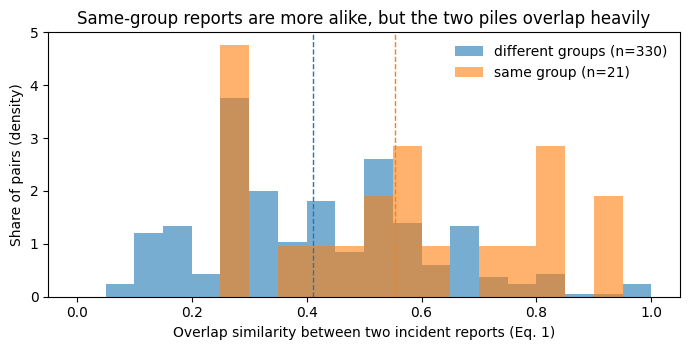

Saved: ../results/improvements/B2_same_vs_different.png
76 of 330 different-group pairs (23%) are more alike than the average same-group pair.

In plain words: reports from the same group share 55% of techniques on average, reports from different groups 41%. Random name tags almost never produce this gap (p = 0.005), so TTPs do carry a real signal. But different groups still share 41%: a clue that narrows the field, not proof of who did it.


In [9]:
def similarity_matrix(df, sim):
    X = df.to_numpy()
    n = len(X)
    S = np.full((n, n), np.nan)
    for i in range(n):
        for j in range(i + 1, n):
            S[i, j] = sim(X[i], X[j])
    return S

def same_vs_different(S, labs):
    iu = np.triu_indices(len(labs), k=1)
    same = labs[iu[0]] == labs[iu[1]]
    vals = S[iu]
    return vals[same], vals[~same]

def shuffle_test(S, labs, n=N_SHUFFLES, seed=SEED):
    rng = np.random.default_rng(seed)
    s, d = same_vs_different(S, labs)
    real_gap = s.mean() - d.mean()
    hits = 0
    for _ in range(n):
        s2, d2 = same_vs_different(S, rng.permutation(labs))
        hits += (s2.mean() - d2.mean()) >= real_gap
    return s, d, real_gap, (hits + 1) / (n + 1)

S_report = similarity_matrix(comp_df, overlap_similarity)
same, diff, gap, p = shuffle_test(S_report, labels)

b2 = pd.DataFrame([
    {"pile": "same group", "pairs": str(len(same)), "value": round(same.mean(), 3)},
    {"pile": "different groups", "pairs": str(len(diff)), "value": round(diff.mean(), 3)},
    {"pile": "gap (same - different)", "pairs": "-", "value": round(gap, 3)},
    {"pile": f"p-value ({N_SHUFFLES} shuffles)", "pairs": "-", "value": round(p, 4)},
])
display(b2)
save(b2, "B2_shuffle_test")

fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(0, 1, 21)
ax.hist(diff, bins=bins, alpha=0.6, label=f"different groups (n={len(diff)})", density=True)
ax.hist(same, bins=bins, alpha=0.6, label=f"same group (n={len(same)})", density=True)
ax.axvline(diff.mean(), ls="--", lw=1); ax.axvline(same.mean(), ls="--", lw=1, color="C1")
ax.set_xlabel("Overlap similarity between two incident reports (Eq. 1)")
ax.set_ylabel("Share of pairs (density)")
ax.set_title("Same-group reports are more alike, but the two piles overlap heavily")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "B2_same_vs_different.png", dpi=200)
plt.show()
print(f"Saved: {OUT_DIR / 'B2_same_vs_different.png'}")

print(f"{(diff > same.mean()).sum()} of {len(diff)} different-group pairs ({(diff > same.mean()).mean():.0%}) are more alike than the average same-group pair.")
print(f"\nIn plain words: reports from the same group share {same.mean():.0%} of techniques on average, "
      f"reports from different groups {diff.mean():.0%}. Random name tags almost never produce this gap "
      f"(p = {p:.3f}), so TTPs do carry a real signal. But different groups still share {diff.mean():.0%}: "
      f"a clue that narrows the field, not proof of who did it.")

## B2b. Nearest-match test: can TTPs name the group?

**Question:** The paper says TTPs are too generic to attribute an attack, but never tries. What happens if we try the simplest way?

**What we do:** Hide the group name of one report, find the *most similar* other report (Eq. 1), and guess its group. Do this for the 16 reports whose group has at least two reports (otherwise there is nothing right to find). This is the "1 nearest neighbour" idea used by attribution models such as KNN, without any training.

**How to read it:** the *hit rate* is how often the guess is right. *Chance* is the hit rate of picking another report at random. Look also at which report is "nearest": Eq. 1 divides by the smaller list, so a tiny report that is a subset of a big one scores a perfect 1.0.

In [10]:
S_full = np.where(np.isnan(S_report), S_report.T, S_report)     # make the matrix symmetric
np.fill_diagonal(S_full, -1)                                     # a report cannot match itself
n_tech = comp_df.sum(axis=1).to_numpy()
group_size = pd.Series(labels).value_counts()

rows = []
for i in range(len(labels)):
    if group_size[labels[i]] < 2:
        continue
    j = int(np.argmax(S_full[i]))
    rows.append({"report": f"{labels[i]} #{comp_df.index[i][1]}", "techniques": int(n_tech[i]),
                 "nearest report": f"{labels[j]} #{comp_df.index[j][1]}", "its techniques": int(n_tech[j]),
                 "similarity": round(S_full[i, j], 2), "same group?": labels[i] == labels[j]})
nn = pd.DataFrame(rows)
display(nn)
save(nn, "B2b_nearest_match")

hits = int(nn["same group?"].sum())
chance = np.mean([(group_size[g] - 1) / (len(labels) - 1) for g in labels if group_size[g] >= 2])
small = nn["its techniques"].min()
print(f"Hit rate: {hits} of {len(nn)} ({hits / len(nn):.0%}); chance: {chance:.0%}.")

# How likely is a hit rate this high from pure guessing? Each report has its own chance of a lucky hit
# (other reports of its group / 26). Combine them exactly and add up the chance of `hits` or more.
probs = [(group_size[g] - 1) / (len(labels) - 1) for g in labels if group_size[g] >= 2]
dist = np.array([1.0])
for q in probs:
    dist = np.convolve(dist, [1 - q, q])
p_guess = dist[hits:].sum()
print(f"Random guessing would get {hits} or more right {p_guess:.0%} of the time, so this hit rate is not clearly better than guessing.")
print(f"{(nn['its techniques'] == small).sum()} reports were matched to a report with only {small} techniques.")

,report,techniques,nearest report,its techniques,similarity,same group?
0,Blackcat #0,22,Blackcat #2,17,0.94,True
1,Blackcat #1,20,Lockbit #5,24,0.85,False
2,Blackcat #2,17,ESXIArgs #18,3,1.00,False
3,Blackcat #3,24,Blackcat #4,15,0.93,True
4,Blackcat #4,15,ESXIArgs #18,3,1.00,False
5,Lockbit #5,24,Play #9,12,0.92,False
6,Lockbit #6,25,Blackcat #4,15,0.87,False
7,Lockbit #7,20,ESXIArgs #18,3,1.00,False
8,Play #8,20,Play #9,12,0.83,True
9,Play #9,12,Lockbit #5,24,0.92,False


Saved: ../results/improvements/B2b_nearest_match.csv
Hit rate: 3 of 16 (19%); chance: 10%.
Random guessing would get 3 or more right 21% of the time, so this hit rate is not clearly better than guessing.
5 reports were matched to a report with only 3 techniques.


## C1. Techniques everyone uses

**Question:** If every ransomware group encrypts files, does "encrypted files" help you tell who did it?

**What we do:** Count how many of the 16 groups in the company data use each technique entry, and list the 10 most common. Then repeat the B2 comparison using only **less common** entries (used by fewer than half of the groups).

**How to read it:** common techniques are background noise for attribution. If the gap between *same group* and *different groups* widens without them, the useful signal sits in the rarer techniques.

In [11]:
share_of_groups = comp_prof.mean().sort_values(ascending=False)   # share of the 16 groups using each entry
top10 = pd.DataFrame({"technique entry (tactic : technique : sub-technique)": [" : ".join(map(str, c)) for c in share_of_groups.index[:10]],
                      "groups using it (of 16)": (share_of_groups.values[:10] * len(comp_prof)).round().astype(int),
                      "share": (share_of_groups.values[:10] * 100).round().astype(int).astype(str) + "%"})
display(top10)
save(top10, "C1_most_common_techniques")

rare_cols = share_of_groups[share_of_groups < 0.5].index
rare = comp_df[rare_cols]
keep = rare.sum(axis=1).to_numpy() > 0          # a report with no rare entries cannot be compared
S_rare = similarity_matrix(rare[keep], overlap_similarity)
same_r, diff_r, gap_r, p_r = shuffle_test(S_rare, labels[keep])

c1 = pd.DataFrame([
    {"entries used": f"all ({comp_df.shape[1]})", "reports": len(labels), "same group": round(same.mean(), 2),
     "different groups": round(diff.mean(), 2), "gap": round(gap, 2), "p-value": round(p, 4)},
    {"entries used": f"less common only ({len(rare_cols)})", "reports": int(keep.sum()), "same group": round(same_r.mean(), 2),
     "different groups": round(diff_r.mean(), 2), "gap": round(gap_r, 2), "p-value": round(p_r, 4)},
])
display(c1)
save(c1, "C1_common_vs_rare")
used_by_all = int((share_of_groups == 1).sum())
print(f"\nIn plain words: {used_by_all} technique entr{'y is' if used_by_all == 1 else 'ies are'} used by all 16 groups, so "
      f"{'it says' if used_by_all == 1 else 'they say'} nothing about who attacked. Without the common entries, different groups "
      f"share {diff_r.mean():.0%}, while same-group reports share {same_r.mean():.0%}.")

,technique entry (tactic : technique : sub-technique),groups using it (of 16),share
0,Impact : Data Encrypted for Impact : NoSubTechnique,16,100%
1,Initial Access : External Remote Services : NoSubTechnique,12,75%
2,Persistence : External Remote Services : NoSubTechnique,12,75%
3,Defense Evasion : Impair Defenses : Disable or Modify Tools,10,62%
4,Command and Control : Remote Access Software : NoSubTechnique,9,56%
5,Execution : Command and Scripting Interpreter : PowerShell,9,56%
6,Lateral Movement : Remote Services : Remote Desktop Protocol,9,56%
7,Privilege Escalation : Valid Accounts : Domain Accounts,8,50%
8,Initial Access : Exploit Public-Facing Application : NoSubTechnique,8,50%
9,Discovery : Network Service Discovery : NoSubTechnique,7,44%


Saved: ../results/improvements/C1_most_common_techniques.csv


,entries used,reports,same group,different groups,gap,p-value
0,all (887),27,0.55,0.41,0.14,0.005
1,less common only (878),27,0.48,0.23,0.25,0.002


Saved: ../results/improvements/C1_common_vs_rare.csv

In plain words: 1 technique entry is used by all 16 groups, so it says nothing about who attacked. Without the common entries, different groups share 23%, while same-group reports share 48%.


## C2. Clue scorecard: what each source sees

**Question:** Does any single source see the whole picture of a group? And how many TTPs are strong enough to rely on?

**What we do:**
1. For each group that appears in both sources, count the techniques seen by **both**, by the **company only** and by **CISA only**. This is the "blind men and the elephant" problem: each source touches a different part.
2. Grade every technique of that group like an intelligence report is graded, with two simple and transparent rules instead of a black-box model:
   - **Corroborated?** Seen by both independent sources.
   - **Distinctive?** Used by fewer than 25% of all 29 group profiles (16 company + 13 CISA).

| Grade | Corroborated | Distinctive | Meaning |
|---|---|---|---|
| **Strong clue** | yes | yes | worth following up |
| Common, confirmed | yes | no | true but does not point to anyone |
| Unverified lead | no | yes | interesting, needs a second source |
| Weak | no | no | little value for attribution |

**How to read it:** the *strong clue* column shows how much TTP evidence could support an attribution decision.

In [12]:
all_profiles = pd.concat([comp_prof.astype(bool), cisa_prof.astype(bool)])
group_share = all_profiles.mean()          # share of the 29 group profiles using each column
distinctive = group_share < 0.25

island, strong_list = [], []
for c, k in COMP_TO_CISA.items():
    if c in ("Blacksuit", "8base"):        # second names for groups already listed (rebrand or affiliate)
        continue
    a, b = comp_prof.loc[c].astype(bool), cisa_prof.loc[k].astype(bool)
    union = a | b
    both = a & b
    island.append({
        "group (company / CISA)": f"{c} / {k}",
        "seen by both": int(both.sum()), "company only": int((a & ~b).sum()), "CISA only": int((b & ~a).sum()),
        "company sees": f"{a.sum() / union.sum():.0%}", "CISA sees": f"{b.sum() / union.sum():.0%}",
        "strong clues": int((both & distinctive).sum()),
        "common, confirmed": int((both & ~distinctive).sum()),
        "unverified leads": int((union & ~both & distinctive).sum()),
        "weak": int((union & ~both & ~distinctive).sum()),
        "link uncertain?": "yes (#?)" if c in uncertain else "no",
    })
    for col in both[both & distinctive].index:
        strong_list.append({"group": c, "strong clue (tactic: technique - sub-technique)": " : ".join(col)})

island_df = pd.DataFrame(island)
display(island_df)
save(island_df, "C2_information_islands_scorecard")

strong_df = pd.DataFrame(strong_list)
display(strong_df)
save(strong_df, "C2_strong_clues_list")
print(f"\nIn plain words: no source sees everything. Out of up to {island_df[['seen by both','company only','CISA only']].sum(axis=1).max()} "
      f"techniques per group, only {island_df['strong clues'].min()}-{island_df['strong clues'].max()} are both confirmed by "
      f"two sources and distinctive. Royal's CISA source is missing from the artifact (see A3).")

,group (company / CISA),seen by both,company only,CISA only,company sees,CISA sees,strong clues,"common, confirmed",unverified leads,weak,link uncertain?
0,Blackcat / ALPHV,2,41,8,84%,20%,1,1,33,16,no
1,Lockbit / Lockbit,9,33,51,45%,65%,0,9,70,14,no
2,Play / Play,10,18,8,78%,50%,1,9,18,8,no
3,Blackbasta / Black Basta,7,19,16,62%,55%,0,7,25,10,no
4,Royal / Royal,9,12,37,36%,79%,1,8,36,13,no
5,Carver Phobos / Phobos,8,27,41,46%,64%,3,5,56,12,yes (#?)


Saved: ../results/improvements/C2_information_islands_scorecard.csv


,group,strong clue (tactic: technique - sub-technique)
0,Blackcat,Credential Access : Steal or Forge Kerberos Tickets : Kerberoasting
1,Play,Collection : Archive Collected Data : Archive via Utility
2,Royal,Defense Evasion : Indicator Removal : Clear Windows Event Logs
3,Carver Phobos,Credential Access : OS Credential Dumping : Cached Domain Credentials
4,Carver Phobos,Credential Access : Brute Force : Password Guessing
5,Carver Phobos,Persistence : Boot or Logon Autostart Execution : Registry Run Keys / Startup Folder


Saved: ../results/improvements/C2_strong_clues_list.csv

In plain words: no source sees everything. Out of up to 93 techniques per group, only 0-3 are both confirmed by two sources and distinctive. Royal's CISA source is missing from the artifact (see A3).


**Does the 25% cut-off matter?** The cut-off for "distinctive" was chosen for clarity, not tuned. The table below repeats the count of strong clues with stricter (10%) and looser (50%) cut-offs.

In [13]:
rows = []
for cut in [0.10, 0.25, 0.50]:
    dist_cut = group_share < cut
    row = {"distinctive = used by fewer than": f"{cut:.0%} of groups"}
    for c, k in COMP_TO_CISA.items():
        if c in ("Blacksuit", "8base"):
            continue
        both = comp_prof.loc[c].astype(bool) & cisa_prof.loc[k].astype(bool)
        row[c] = int((both & dist_cut).sum())
    row["total"] = sum(v for key, v in row.items() if key != "distinctive = used by fewer than")
    rows.append(row)
sens_df = pd.DataFrame(rows)
display(sens_df)
save(sens_df, "C2_cutoff_sensitivity")

,distinctive = used by fewer than,Blackcat,Lockbit,Play,Blackbasta,Royal,Carver Phobos,total
0,10% of groups,0,0,0,0,0,0,0
1,25% of groups,1,0,1,0,1,3,6
2,50% of groups,1,5,6,4,5,5,26


Saved: ../results/improvements/C2_cutoff_sensitivity.csv


## A4. Summary: what the paper says, what we found, and what it means

**Question:** Taken together, should a reader trust the paper's conclusion?

**What we do:** Collect the findings above into one table. The numbers are filled in from this run, not typed by hand.

**How to read it:** the last column says whether each finding changes the paper's main message.

In [14]:
summary = pd.DataFrame([
    {"topic": "Reproducibility", "paper": "Results produced by the released notebook",
     "we found": f"{n_ok}/{len(ledger_df)} headline numbers and {full['match'].sum()}/{len(full)} table values reproduced; setup needed Python <3.14 (A1, A2, A2b)",
     "effect on conclusion": "Supports trust in the computation"},
    {"topic": "Metric", "paper": "Tables 5-6 use overlap (Eq. 1): same group 0.37, different groups 0.21",
     "we found": f"Code uses containment; with Eq. 1: same group {t5_ov_avg:.2f}, different groups {cross_ov:.2f} (B1)",
     "effect on conclusion": "Numbers need correcting; the paper understates how alike groups are"},
    {"topic": "Signal vs chance", "paper": "Only averages, no statistical test",
     "we found": f"Same-group reports more alike ({same.mean():.2f} vs {diff.mean():.2f}, p = {p:.3f}) (B2)",
     "effect on conclusion": "TTPs are a real clue, but too shared to be proof"},
    {"topic": "Attribution test", "paper": "Claims TTPs cannot attribute, but never tries",
     "we found": f"Nearest-match guess right {hits} of {len(nn)} times (chance {chance:.0%}) (B2b)",
     "effect on conclusion": "Directly supports the paper's central claim"},
    {"topic": "Study design", "paper": "Table 5 (single reports) is compared with Table 6 (combined group profiles)",
     "we found": "Combined profiles share more by construction; comparing single reports on both sides gives a fairer test (B2)",
     "effect on conclusion": "Compare like with like in future work"},
    {"topic": "Common techniques", "paper": "Not analysed",
     "we found": f"{used_by_all} entr{'y' if used_by_all == 1 else 'ies'} used by all 16 groups; without common entries: same group {same_r.mean():.2f} vs different {diff_r.mean():.2f} (C1)",
     "effect on conclusion": "Weight rare techniques more than common ones"},
    {"topic": "Information islands", "paper": "Company and CISA overlap about 0.35",
     "we found": f"Each source misses part of every group; only {island_df['strong clues'].min()}-{island_df['strong clues'].max()} strong clues per group (C2)",
     "effect on conclusion": "Supports the paper's call for data sharing"},
    {"topic": "Sources", "paper": "13 CISA reports, all published in 2023",
     "we found": f"{(audit_df['in Appendix D'] == 'no').sum()} report (Royal) missing; {(audit_df['check'].str.contains('2024')).sum()} issued in 2024; 1 impossible date; Excel = data files (A3)",
     "effect on conclusion": "Documentation needs an erratum; results unaffected"},
])
display(summary)
save(summary, "A4_summary")
print("\nMain message: TTPs are a clue, not proof. The paper's direction holds, but it understates how similar "
      "ransomware groups are, and each source sees only part of the picture.")

,topic,paper,we found,effect on conclusion
0,Reproducibility,Results produced by the released notebook,"15/15 headline numbers and 248/248 table values reproduced; setup needed Python <3.14 (A1, A2, A2b)",Supports trust in the computation
1,Metric,"Tables 5-6 use overlap (Eq. 1): same group 0.37, different groups 0.21","Code uses containment; with Eq. 1: same group 0.44, different groups 0.45 (B1)",Numbers need correcting; the paper understates how alike groups are
2,Signal vs chance,"Only averages, no statistical test","Same-group reports more alike (0.55 vs 0.41, p = 0.005) (B2)","TTPs are a real clue, but too shared to be proof"
3,Attribution test,"Claims TTPs cannot attribute, but never tries",Nearest-match guess right 3 of 16 times (chance 10%) (B2b),Directly supports the paper's central claim
4,Study design,Table 5 (single reports) is compared with Table 6 (combined group profiles),Combined profiles share more by construction; comparing single reports on both sides gives a fairer test (B2),Compare like with like in future work
5,Common techniques,Not analysed,1 entry used by all 16 groups; without common entries: same group 0.48 vs different 0.23 (C1),Weight rare techniques more than common ones
6,Information islands,Company and CISA overlap about 0.35,Each source misses part of every group; only 0-3 strong clues per group (C2),Supports the paper's call for data sharing
7,Sources,"13 CISA reports, all published in 2023",1 report (Royal) missing; 3 issued in 2024; 1 impossible date; Excel = data files (A3),Documentation needs an erratum; results unaffected


Saved: ../results/improvements/A4_summary.csv

Main message: TTPs are a clue, not proof. The paper's direction holds, but it understates how similar ransomware groups are, and each source sees only part of the picture.
